# Task 1: atmosphere and geometry checks

Validate the 1,000 km atmosphere, 550 km watched shell, launch boundary and positive material atom counts. The existing 200 km / 33.5 km case is compared against the original writer at Git commit `7a93224`.

These are geometry-file checks. They do not initialize Geant4, simulate transport, or change reflected-photon handling. Generated files go to a temporary directory, not the repository.


In [1]:
from pathlib import Path
import sys, tempfile, json
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "cosi_atmosphere/response/MassModels.py").is_file())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "validation"))
from check_geometry import run_checks, BASELINE_COMMIT
import cosi_atmosphere.response.MassModels as mass_models

print("Python:", sys.executable)
print("Module:", mass_models.__file__)
print("Original writer:", BASELINE_COMMIT)
print({p: version(p) for p in ["cosi-atmosphere", "pymsis", "numpy", "pandas"]})


Python: /home/jooyunw/.conda/envs/cosi-atmosphere/bin/python
Module: /project/ckarwin/astro/jooyun/cosi-atmosphere/cosi-atmosphere/cosi_atmosphere/response/MassModels.py
Original writer: 7a93224
{'cosi-atmosphere': '0.1.7', 'pymsis': '0.13.0', 'numpy': '2.2.6', 'pandas': '2.3.3'}


## Controlled profiles and checks

The script creates 100 m altitude grids using MSIS 2.1, with fixed date 2016-06-13 12:00 UTC, longitude −107.38°, latitude −5.66°, F10.7 = F10.7a = 100 and all Ap inputs = 4. Explicit solar inputs avoid a data download. These are controlled test profiles, not a reproduction of the historical atmosphere.

Checks cover every shell's boundaries, density and elemental counts; the watched shell and source boundary; the original writer's zero-count failure; exact balloon-geometry regression with fixed visualization colors; and invalid grids/watched altitudes. Invalid input must leave an existing geometry file untouched. Restart the kernel after editing the module or check script.


In [2]:
workspace = tempfile.TemporaryDirectory(prefix="cosi-geometry-notebook-")
work = Path(workspace.name)
results = run_checks(work)
print(json.dumps(results, indent=2))


/project/ckarwin/astro/jooyun/cosi-atmosphere/cosi-atmosphere/cosi_atmosphere/response/MassModels.py:29: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(atmosphere_file, delim_whitespace=True, **kwargs)


/project/ckarwin/astro/jooyun/cosi-atmosphere/cosi-atmosphere/cosi_atmosphere/response/MassModels.py:29: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(atmosphere_file, delim_whitespace=True, **kwargs)


{
  "balloon": {
    "top_km": 200.0,
    "watch_km": 33.5,
    "shells": 2000,
    "source_radius_km": 6578.0,
    "omitted_zero_components": 911
  },
  "orbital": {
    "top_km": 1000.0,
    "watch_km": 550.0,
    "shells": 10000,
    "source_radius_km": 7378.0,
    "omitted_zero_components": 7281
  },
  "balloon_matches_original": true,
  "original_orbital_zero_components": 6370,
  "rejected_invalid_inputs": 7,
  "transport": "Not run; these checks validate generated geometry, not Geant4 initialization or physics."
}


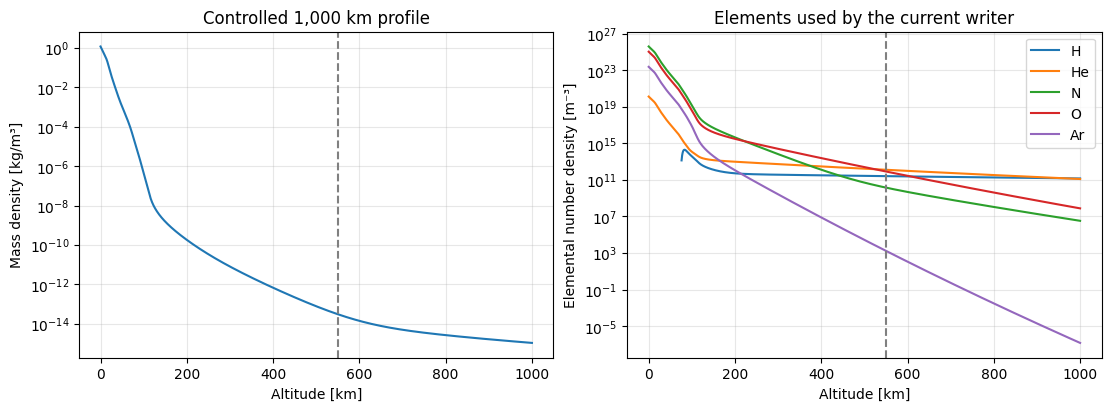

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

profile = pd.read_csv(work / "profile_1000.dat", sep="\t")
altitude = profile["altitude[km]"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].semilogy(altitude, profile["mass_density[kg/m3]"])
axes[0].set(xlabel="Altitude [km]", ylabel="Mass density [kg/m³]", title="Controlled 1,000 km profile")
components = {"H": profile["H[m-3]"], "He": profile["He[m-3]"],
              "N": profile["N[m-3]"] + 2 * profile["N2[m-3]"],
              "O": profile["O[m-3]"] + 2 * profile["O2[m-3]"],
              "Ar": profile["Ar[m-3]"]}
for element, density in components.items():
    axes[1].semilogy(altitude, density.where(density > 0), label=element)
axes[1].set(xlabel="Altitude [km]", ylabel="Elemental number density [m⁻³]", title="Elements used by the current writer")
axes[1].legend()
for ax in axes:
    ax.axvline(550, color="gray", linestyle="--", label="Watched altitude")
    ax.grid(alpha=.3)
display(fig)
plt.close(fig)


## What remains to check

Load the generated geometry in MEGAlib/Cosima and perform a small reviewed run. That will check actual material/geometry initialization and source generation. It has not been run by this notebook. Reflected-photon selection remains outside this change.


In [4]:
workspace.cleanup()
print("Temporary geometry and profile files removed; results and plots remain in this notebook.")


Temporary geometry and profile files removed; results and plots remain in this notebook.
